# **Task 3: Satellite Embeddings**

This notebook demonstrates two powerful applications of Google's  satellite embeddings:
1.  **Similarity Search**: Finding areas that are structurally similar to a chosen point.
2.  **Land Cover Classification**: Training a machine learning model to classify land cover based on embedding vectors.

## **Initial Setup**

We need to import the necessary Python package for this task. We also need to authenticate and initialize the Earth Engine package with our credentials.

If you don't have your credentials yet, please refer to the "***Registration to Earth Engine - Step by Step guide***" PDF on NTU Learn

In [1]:
import ee
import geemap
import datetime as dt

ee.Authenticate()
ee.Initialize(project="YOUR_PROJECTID") # Replace with your project's ID

---
# **Part 1: Finding Similar Areas with Dot Product**

In this part, we'll pick a point in New York City and use the satellite embeddings to find other areas in the region that have a similar physical structure (e.g., finding other dense urban cores, parks, or industrial zones).


## **Step 1. Define Parameters and Create an Interactive Map**

Let's start by defining our core parameters: the point of interest (a location in NYC) and the year we want to analyze. We'll also create the `geemap` interactive map that we'll add our results to.

In [2]:
# Create an interactive map object centered on our area
m = geemap.Map(center=[40.76, -73.98], zoom=11)

# Define the point of interest (in New York City)
point = ee.Geometry.Point([-73.981191, 40.762779])
year = 2024


# Adding a satellite imagery basemap
m.add_basemap('SATELLITE')

# Display the map
m

Map(center=[40.76, -73.98], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright…

## **Step 2. Load and Prepare Embedding Data**
The **`GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL`** collection contains global, pre-computed vector embeddings for each year. We'll filter this collection to get the data for our chosen year and then mosaic it into a single, cloud-free image for our analysis.

In [3]:
# Load the annual satellite embedding ImageCollection
embeddings = ee.ImageCollection('GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL')

# Filter the collection for the specified year and create a single mosaic image
mosaic = embeddings.filterDate(f'{year}-01-01', f'{year+1}-01-01').mosaic()
band_names = mosaic.bandNames()

## **Step 3. Define the Similarity Calculation Logic**
To find "similar" areas, we will calculate the **dot product** between the embedding vector at our point of interest and the vector at every other pixel in the image. A higher dot product (closer to 1) means the vectors are more aligned and thus more similar.

We'll define this logic inside a function that can be run on Google's servers.

In [4]:
def get_dot_product(feature):
  # 1. Create an image from the feature's vector. Every pixel in this image
  #    will contain the embedding vector from our point of interest.
  point_image = ee.Image(feature.toArray(band_names)).arrayFlatten([band_names])

  # 2. Calculate the dot product by multiplying band-by-band and summing.
  dot_product = point_image.multiply(mosaic).reduce('sum')
  return dot_product

## **Step 4. Execute the Similarity Calculation**
Now we execute the search. We first `.sample()` the mosaic to get the embedding vector at our specific point. Then, we use `.map()` to apply the `get_dot_product` function to that sample, which calculates the similarity across the entire image.

In [5]:
# The result of the .map() is an ImageCollection, so we cast it to an Image.
similarity = ee.Image(
    mosaic.sample(region=point, scale=10).map(get_dot_product).first()
)

## **Step 5. Visualize the Results**
With the similarity image calculated, we can add it to the map. Let's use a color palette where brighter colors (yellow and white) indicate a higher similarity score.

In [6]:
# Define a color palette for visualization
palette = [
    '000004', '2C105C', '711F81', 'B63679',
    'EE605E', 'FDAE78', 'FCFDBF', 'FFFFFF'
]
vis_params = {'palette': palette, 'min': 0, 'max': 1}

# Add the similarity layer to the map
m.addLayer(similarity, vis_params, 'bright = more similar')

# Add the original point to the map for reference
m.addLayer(point, {'color': 'cyan'}, 'point')

# Add the colorbar for the similiraty map
m.add_colorbar(
    vis_params = vis_params,
    label = 'Cosine Similarity',
    orientation = "horizontal", # or 'vertical'
    position = 'bottomright', # other options: 'bottomleft', 'topright'
    layer_name = 'bright = more similar'

)

print("[LAYER ADDED TO MAP]: Similarity image has been added to the map\n")


[LAYER ADDED TO MAP]: Similarity image has been added to the map



---
# **Part 2: Land Cover Classification**

Next, we'll use the same embedding data to perform a supervised land cover classification. We'll train a Random Forest model on pre-labeled points and then apply it to classify a new area.


### **Step 6. Set Up Parameters and Training Data**
For this task, we will classify an area in Singapore. We'll load a pre-made `FeatureCollection` asset (`projects/google/glance_with_embeddings`). This dataset contains thousands of points from the **GLanCE** dataset ([details](https://gee-community-catalog.org/projects/glance_training/)) and, that already have their corresponding embedding vectors attached as properties, making it ready for immediate use.


In [7]:
# Define the region of interest for this task (Singapore)
roi = ee.Geometry.Point([103.79206499580852, 1.3922611695527354])
map_year = 2024

# This FeatureCollection contains points with a land cover 'label' and all
# the embedding vectors as properties. This is our training data.
labels_and_vectors = ee.FeatureCollection('EDIT_PROJECTFILE')

In [8]:
# --- Get a summary of the training data ---

# Perform server-side aggregations to get key stats
total_size = labels_and_vectors.size()
split_counts = labels_and_vectors.aggregate_histogram('split')
properties = labels_and_vectors.first().propertyNames()

# Use .getInfo() to bring the results to the notebook
total_size_local = total_size.getInfo()
split_counts_local = split_counts.getInfo()
properties_local = properties.getInfo()

# Count properties that start with 'A' (e.g., 'A00', 'A01', etc.)
embedding_properties = [p for p in properties_local if p.startswith('A')]

# --- Print the formatted summary ---
print("--- Training Data Summary ---")
print(f"Total Labeled Points: {total_size_local:,}")
print(f"Number of Embedding Features (Predictors): {len(embedding_properties)}")
print("------------------------------------")

--- Training Data Summary ---
Total Labeled Points: 34,885
Number of Embedding Features (Predictors): 64
------------------------------------


### A Note on the `labels_and_vectors` Training Data

The `labels_and_vectors` variable is a pre-made `ee.FeatureCollection` from Google's assets, designed for classification tasks. It's a curated dataset containing roughly **35,000 points**. Here’s a quick summary:

* **What it contains:** Each point in this collection has three key components:
    * A **`geometry`**: The point's latitude and longitude.
    * A **`label` property**: The ground-truth land cover class (e.g., 0 for water).
    * **`A*` properties** (e.g., `A00`, `A01`...): The 64 embedding vector values that describe the landscape.

In short, this collection provides a ready-to-use training dataset with input features (embeddings) and the correct output (labels).

| Component | Data Type / Example | Role in our Model |
| :--- | :--- | :--- |
| **`system:footprint`** | `ee.Geometry.Point` | The geographic location of the training sample. |
| **`label`** | `Integer` (e.g., `0`) | The **Target**. The numerical class ID we train the model to predict. |
| **`label_name`** | `String` (e.g., `'water'`) | The human-readable name for the `label`. Useful for context. |
| **`A*`** | `Float` (e.g., `A00`, `A01`...) | The **Predictors**. The 64 vector values that the model learns from. |
| **`split`** | `String` (e.g., `'train'`) | Recommended data split for training vs. testing the model. |

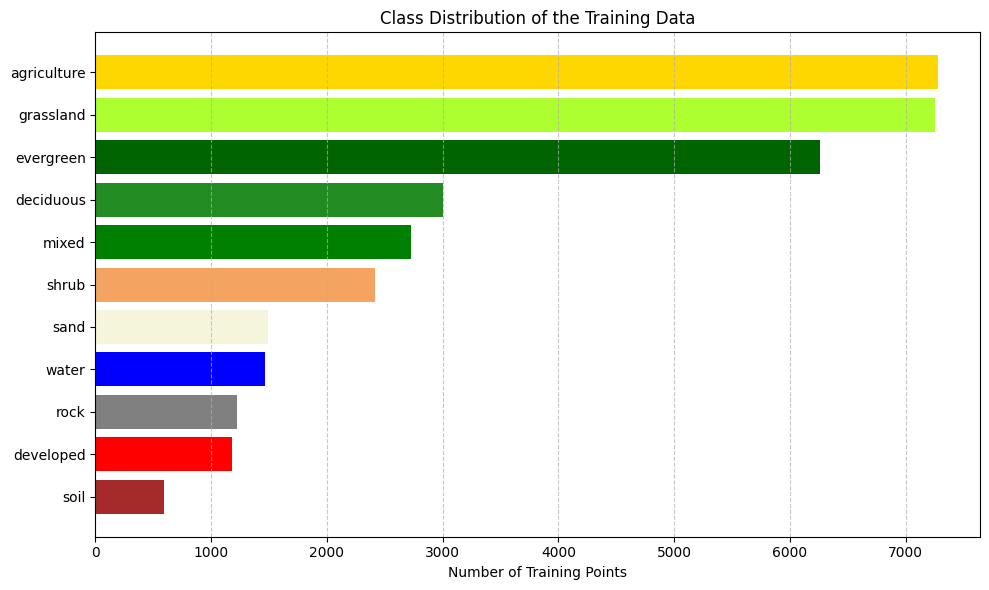

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

# --- 1. Define the color palette and class labels ---

# HEX color palette corresponding to the 11 land-cover classes.
# Each index in this list matches the class ID (0–10).
PALETTE_HEX = [
    '0000FF', 'FF0000', 'A52A2A', '808080', 'F5F5DC', '228B22',
    '006400', '008000', 'F4A460', 'ADFF2F', 'FFD700',
]

# Mapping of class IDs (as strings) to their class names.
# These labels are confirmed to match the color palette and dataset documentation.
CLASS_NAMES = {
    '0': 'water',
    '1': 'developed',
    '2': 'soil',
    '3': 'rock',
    '4': 'sand',
    '5': 'deciduous',
    '6': 'evergreen',
    '7': 'mixed',
    '8': 'shrub',
    '9': 'grassland',
    '10': 'agriculture'
}

# --- 2. Retrieve the class frequency counts from Earth Engine ---

# Count how many training samples belong to each class ID.
# 'labels_and_vectors' is a FeatureCollection where each feature
# has a 'label' property representing its land-cover class.
label_distribution = labels_and_vectors.aggregate_histogram('label').getInfo()

# --- 3. Convert the Earth Engine results into a Pandas DataFrame ---

# Transform the dictionary {class_id: count} into a DataFrame for easier plotting.
df = pd.DataFrame(list(label_distribution.items()), columns=['Class ID', 'Count'])
# Map each numeric class ID to its human-readable class name.
df['Class Name'] = df['Class ID'].map(CLASS_NAMES)
df = df.sort_values('Count', ascending=True)

# Extract colors corresponding to the sorted class order.
sorted_colors = ['#' + PALETTE_HEX[int(cid)] for cid in df['Class ID']]

# --- 4. Create and Display the Bar Chart ---
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(df['Class Name'], df['Count'], color=sorted_colors)
ax.set_xlabel('Number of Training Points')
ax.set_title('Class Distribution of the Training Data')
ax.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

### **Step 7. Train a Random Forest Classifier**
Now we'll train a `smileRandomForest` classifier. We tell the classifier that the pixel values it should use for training are the embedding bands (`inputProperties`) and that the correct answer for each training point is found in the `classProperty`.

In [10]:
# Use the embedding band names as the predictors for the model
input_bands = embeddings.first().bandNames()

# Train the classifier. We set it to 'MULTIPROBABILITY' to get the
# probability of each class, not just the single most likely class.
classifier = (ee.Classifier.smileRandomForest(numberOfTrees=100)
              .train(features=labels_and_vectors,
                     classProperty='label',
                     inputProperties=input_bands)
              .setOutputMode('MULTIPROBABILITY'))

###Note on Classifiers in Earth Engine
In this notebook, we used a Random Forest classifier, but Earth Engine provides several other machine learning methods you can try. Each has different strengths depending on the problem and the dataset. A list of the available classifiers can be found [here](https://developers.google.com/earth-engine/guides/classification#classifier-output-modes)

Here's a summary of some commonly used classifiers available in the API:

| Classifier Method | Earth Engine Name | Best For / Strengths |
| :--- | :--- | :--- |
| **Random Forest** | `ee.Classifier.smileRandomForest` | Robust, general-purpose classification. Widely used for complex remote sensing data. |
| **CART** | `ee.Classifier.smileCart` | Simpler, interpretable models (a single decision tree). Good for understanding feature importance. |
| **Naive Bayes** | `ee.Classifier.smileNaiveBayes` | Probabilistic classification where features are assumed to be independent. |
| **k-Nearest Neighbors** | `ee.Classifier.smileKnn` | Classifying based on the "closest" examples in the training data. |
| **Support Vector Machine**| `ee.Classifier.libsvm` | Finding the optimal boundary between classes, especially in high-dimensional data. |
| **Gradient Boosted Trees**| `ee.Classifier.smileGradientTreeBoost` | High-performance classification, often competitive with or better than Random Forests. |

### **Step 8. Classify the Annual Embedding Image**
With our model trained, we can apply it to the 2024 embedding mosaic. This will produce a multi-band image where each band represents the probability that a pixel belongs to a specific land cover class.

In [11]:
# Get the 2024 embedding mosaic for our region
embeddings_2024 = embeddings.filterDate(f'{map_year}-01-01', f'{map_year+1}-01-01').filterBounds(roi).mosaic()

# Classify the image. The output is a single band containing an array of probabilities.
# We flatten this array into separate bands, one for each class.
class_ids = [str(i) for i in range(11)]
result = embeddings_2024.classify(classifier).arrayFlatten([class_ids])

### **Step 9. Display the Classification Map (single class per pixel)**

Our model outputs a probability for each class at every pixel. To make a clear, easy-to-read map, we’ll convert those probabilities into **one class per pixel** by taking the **highest-probability class** (argmax). Then we’ll color the map using the class palette.

Here is what we are going to do next:
1) Take the winning class per pixel (`argmax`).  
2) Render the result with the class color palette and add a legend.

In [12]:
# --- Create a Classification Map ---

# 1. Convert the 11 probability bands to an array at each pixel.
# 2. Use arrayArgmax() to find the index of the band with the highest value.
#    This index is our final class ID.
# 3. Use arrayGet(0) to flatten the array and create a single-band image
#    where pixel values correspond to the predicted class ID.
single_class_results = result.toArray().arrayArgmax().arrayGet(0)

# Define how the classified map will be displayed:
#   - Each class ID is colored using its corresponding hex color in PALETTE_HEX.
#   - 'min' and 'max' define the numeric range of class IDs (0–10).
vis_params = {
    'min': 0,
    'max': 10,
    'palette': PALETTE_HEX
}

# --- Display the Map ---
# Create a new interactive map and add a satellite basemap for context.
m2 = geemap.Map()
m2.add_basemap('SATELLITE')

# Add the classified land cover map, using the visualization parameters above.
m2.addLayer(single_class_results, vis_params, f'Land Cover Classification Results — {map_year}')
m2.addLayer(roi, {'color': 'cyan'}, 'ROI')

m2.centerObject(roi, 11)


legend_dict = {CLASS_NAMES[str(i)]: f'#{PALETTE_HEX[i]}' for i in range(11)}

# Add the legend to the map.
# We use a try-except block here to skip gracefully if there is any widget conflict
try:
    m2.add_legend(title='Class', legend_dict=legend_dict)
except Exception as e:
    print('Legend skipped:', e)

m2

Map(center=[1.3922611695527356, 103.79206499580853], controls=(WidgetControl(options=['position', 'transparent…

In [13]:
# --- Define a bounding box over Singapore ---
# Coordinates in [minLon, minLat, maxLon, maxLat] format
singapore_bbox = ee.Geometry.Rectangle([103.6, 1.2, 104.1, 1.48])

# Optional: visualize the region on the map
m2.addLayer(singapore_bbox, {'color': 'yellow'}, 'Singapore Bounding Box')
m2.centerObject(singapore_bbox, 10)

# --- Clip and Export ---
classified_clipped = single_class_results.clip(singapore_bbox)

export_name = f'landcover_classification_{map_year}'
task = ee.batch.Export.image.toDrive(
    image=classified_clipped.byte(),
    description=export_name,
    folder='gee_exports',
    fileNamePrefix=export_name,
    region=singapore_bbox,
    scale=10,
    maxPixels=1e13
)
task.start()

print(f"Export started: {export_name}. Check the 'Tasks' tab or Colab logs.")


Export started: landcover_classification_2024. Check the 'Tasks' tab or Colab logs.


---

## Questions for Reflection

- **Similarity Search**

  - When you change the **area** or the **time period**, how do the **most similar areas** change?   

- **Per-pixel Classification**
  - What is the main advantage of training a classifier on **embeddings** instead of raw satellite bands?
*Hint: Think about what information embeddings already capture.*

- **In one or two sentences**
  - how are **the satellite embeddings** different from indices like **NDVI**?
  - In your opinion, where could **similarity search** or **embedding-based classification** be useful in real-world applications?  
---

# Optional Questions

### Part 1 – Similarity Search
-  Choose a **feature or landscape type** that interests you (e.g., volcanoes, lakes, deserts, mudflats, mangrove forest, peatlands, etc).  
-  Use the **similarity search function** to find other locations that look visually or contextually similar.


---

### Part 2 – Classification Map Evaluation
1. Inspect the **classification map** created in Part 2 of this task.  
2. Compare it to the **satellite basemap**.

> *We will assume the satellite basemap and satellite embedding dataset correspond to the same year*

---

### 3. Reflection Questions
- Review and answer the guiding questions provided in the notebook.



